# Movie Recommendation System using NLP & Streamlit

### Objective:

This project builds an intelligent **movie recommender system** that suggests similar movies based on a given input title. By combining **Natural Language Processing (NLP)** techniques with **TF-IDF vectorization** and **cosine similarity**, the system analyzes movie metadata (genres, keywords, and overviews) to find and recommend the most relevant films. It is deployed as a web application using **Streamlit** and enhanced visually using **TMDb API** for fetching movie posters.

---

### Workflow Overview:

* **Import Libraries** – Load essential packages for text processing, vectorization, and web deployment
* **Load & Clean Dataset** – Read CSV data and handle missing values
* **Combine Textual Features** – Merge genres, keywords, and overview into a single text feature
* **Preprocessing** – Clean text, remove stopwords, and tokenize using NLTK
* **TF-IDF Vectorization** – Convert text into numerical vectors
* **Similarity Computation** – Use cosine similarity to find closest movies
* **Poster Fetching (API Integration)** – Retrieve movie posters using TMDb API
* **Recommendation Engine** – Recommend top 5 similar movies for a given input title
* **Streamlit UI** – Build a user-friendly web interface for movie search and results display

---

### Problem Type:

Unsupervised Learning – **Content-Based Recommendation**

---

### Dataset:

**Source:** Local CSV dataset (`movies.csv`)
**Main Fields Used:**

* `genres` – Movie genres (Action, Comedy, etc.)
* `keywords` – Descriptive tags and themes
* `overview` – Movie summary
* `title` – Movie title
* `id` – Unique identifier used to fetch posters from TMDb

---

### Output:

A web-based application that recommends **5 similar movies** based on user input and displays their **titles and posters** using data fetched live from TMDb.



# Step - 1
### Importing Dependencies



In [1]:
# NumPy: For numerical operations and handling arrays
import numpy as np

# Pandas: For working with datasets, dataframes, and CSVs
import pandas as pd

# Matplotlib: For creating static visualizations like line plots, bar charts, etc.
import matplotlib.pyplot as plt

# TfidfVectorizer: Converts text documents into a matrix of TF-IDF features (used for NLP feature extraction)
from sklearn.feature_extraction.text import TfidfVectorizer

# Cosine Similarity: Measures the cosine of the angle between two vectors (used for text similarity)
from sklearn.metrics.pairwise import cosine_similarity

# WordCloud: To generate visual representation of word frequency
from wordcloud import WordCloud

# re: Regular expressions module (used for cleaning text)
import re

# NLTK (Natural Language Toolkit): Popular NLP toolkit in Python
import nltk

# Stopwords: Common words (like 'the', 'is') that are usually removed during preprocessing
from nltk.corpus import stopwords

# Tokenizer: Breaks sentences into words (tokens)
from nltk.tokenize import word_tokenize

# Step - 2
### Data Collection and Preprocessing

In [7]:
# Load the movies dataset
movies = pd.read_csv("/content/movies.csv")

In [8]:
# Check the shape of the dataset (rows, columns)
movies.shape

(4803, 24)

In [9]:
# Preview the first 5 rows of the dataset
movies.head()

,index,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew,director
0,0,237000000,Action Adventure Fantasy Science Fiction,http://www.avatarmovie.com/,19995,culture clash future space war space colony so...,en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Sam Worthington Zoe Saldana Sigourney Weaver S...,"[{'name': 'Stephen E. Rivkin', 'gender': 0, 'd...",James Cameron
1,1,300000000,Adventure Fantasy Action,http://disney.go.com/disneypictures/pirates/,285,ocean drug abuse exotic island east india trad...,en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Johnny Depp Orlando Bloom Keira Knightley Stel...,"[{'name': 'Dariusz Wolski', 'gender': 2, 'depa...",Gore Verbinski
2,2,245000000,Action Adventure Crime,http://www.sonypictures.com/movies/spectre/,206647,spy based on novel secret agent sequel mi6,en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Daniel Craig Christoph Waltz L\u00e9a Seydoux ...,"[{'name': 'Thomas Newman', 'gender': 2, 'depar...",Sam Mendes
3,3,250000000,Action Crime Drama Thriller,http://www.thedarkknightrises.com/,49026,dc comics crime fighter terrorist secret ident...,en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,Christian Bale Michael Caine Gary Oldman Anne ...,"[{'name': 'Hans Zimmer', 'gender': 2, 'departm...",Christopher Nolan
4,4,260000000,Action Adventure Science Fiction,http://movies.disney.com/john-carter,49529,based on novel mars medallion space travel pri...,en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,Taylor Kitsch Lynn Collins Samantha Morton Wil...,"[{'name': 'Andrew Stanton', 'gender': 2, 'depa...",Andrew Stanton


In [10]:
# Display detailed information about the dataset
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 4803 non-null   int64  
 1   budget                4803 non-null   int64  
 2   genres                4775 non-null   object 
 3   homepage              1712 non-null   object 
 4   id                    4803 non-null   int64  
 5   keywords              4391 non-null   object 
 6   original_language     4803 non-null   object 
 7   original_title        4803 non-null   object 
 8   overview              4800 non-null   object 
 9   popularity            4803 non-null   float64
 10  production_companies  4803 non-null   object 
 11  production_countries  4803 non-null   object 
 12  release_date          4802 non-null   object 
 13  revenue               4803 non-null   int64  
 14  runtime               4801 non-null   float64
 15  spoken_languages     

Sample output explanation:
- 4803 movies (rows), 24 columns
- Some important columns: 'genres', 'keywords', 'overview', 'cast', 'director'
- Some columns have missing values (e.g., 'tagline', 'cast', 'overview')

# Step - 3
### Selecting Relevant Columns

In [27]:
# Focus on columns useful for content-based recommendation
required_columns = ['genres' , 'keywords' , 'overview' , 'title']

movies = movies[required_columns]

In [28]:
movies.head()

,genres,keywords,overview,title
0,Action Adventure Fantasy Science Fiction,culture clash future space war space colony so...,"In the 22nd century, a paraplegic Marine is di...",Avatar
1,Adventure Fantasy Action,ocean drug abuse exotic island east india trad...,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End
2,Action Adventure Crime,spy based on novel secret agent sequel mi6,A cryptic message from Bond’s past sends him o...,Spectre
3,Action Crime Drama Thriller,dc comics crime fighter terrorist secret ident...,Following the death of District Attorney Harve...,The Dark Knight Rises
4,Action Adventure Science Fiction,based on novel mars medallion space travel pri...,"John Carter is a war-weary, former military ca...",John Carter


In [29]:
# Check missing values
movies.isnull().sum()

,0
genres,0
keywords,0
overview,0
title,0


In [30]:
# Drop rows with missing values and reset index
movies = movies.dropna().reset_index(drop = True)

In [31]:
movies.isnull().sum()

,0
genres,0
keywords,0
overview,0
title,0


# Step - 4
### Combining Text Features

In [32]:
# Combine genres, keywords, and overview into a single text column
movies['combined'] = movies['genres'] + ' ' + movies['keywords'] + ' ' + movies['overview']

In [18]:
movies.head()

,genres,keywords,overview,title,combined
0,Action Adventure Fantasy Science Fiction,culture clash future space war space colony so...,"In the 22nd century, a paraplegic Marine is di...",Avatar,Action Adventure Fantasy Science Fiction cultu...
1,Adventure Fantasy Action,ocean drug abuse exotic island east india trad...,"Captain Barbossa, long believed to be dead, ha...",Pirates of the Caribbean: At World's End,Adventure Fantasy Action ocean drug abuse exot...
2,Action Adventure Crime,spy based on novel secret agent sequel mi6,A cryptic message from Bond’s past sends him o...,Spectre,Action Adventure Crime spy based on novel secr...
3,Action Crime Drama Thriller,dc comics crime fighter terrorist secret ident...,Following the death of District Attorney Harve...,The Dark Knight Rises,Action Crime Drama Thriller dc comics crime fi...
4,Action Adventure Science Fiction,based on novel mars medallion space travel pri...,"John Carter is a war-weary, former military ca...",John Carter,Action Adventure Science Fiction based on nove...


In [33]:
# Create a working DataFrame for model input
data = movies[[ 'title','combined']]

In [34]:
data.head()

,title,combined
0,Avatar,Action Adventure Fantasy Science Fiction cultu...
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action ocean drug abuse exot...
2,Spectre,Action Adventure Crime spy based on novel secr...
3,The Dark Knight Rises,Action Crime Drama Thriller dc comics crime fi...
4,John Carter,Action Adventure Science Fiction based on nove...


# Step - 5
### WordCloud Visualization

In [38]:
# Generate a WordCloud to show most frequent words

# Combine all movie text data into one large string
# This includes genres, keywords, and overviews for all movies
combined_text = " ".join(movies['combined'])

# Create a WordCloud object with specified width, height, and background color
# The .generate() method processes the text to find word frequencies
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(combined_text)

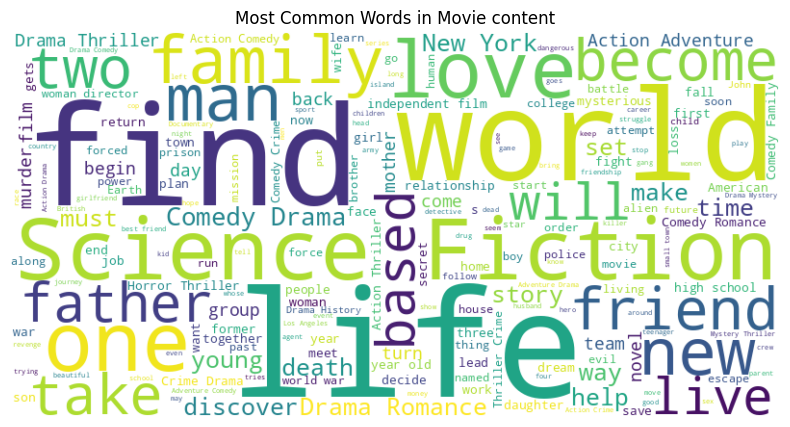

In [39]:
# WordCloud to visualize the most common words in the movie content

# Create a figure with a custom size for better visibility
plt.figure(figsize=(10, 5))

# Display the WordCloud image with smooth interpolation
plt.imshow(wordcloud, interpolation='bilinear')

# Hide the axis for a cleaner visual
plt.axis("off")

# Add a title to the WordCloud plot
plt.title("Most Common Words in Movie content")
plt.show()

# Step - 6
### Preprocessing Text

In [40]:
# Download necessary NLTK data

# Download the Punkt tokenizer models for splitting text into words and sentences
nltk.download('punkt')
nltk.download('punkt_tab')

# Download the list of stopwords to remove common, uninformative words like 'the', 'is', etc.
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [41]:
# Set of English stopwords
stop_words = set(stopwords.words('english'))

In [42]:
# Function to clean and preprocess text
def preprocess_text(text):
    text = re.sub(r"[^a-zA-Z\s]", "", text)      # Remove punctuation/numbers
    text = text.lower()                          # Lowercase
    tokens = word_tokenize(text)                 # Tokenize
    tokens = [word for word in tokens if word not in stop_words]  # Remove stopwords
    return " ".join(tokens)

In [43]:
# Apply preprocessing to the 'combined' text
data = data.copy()  # To avoid SettingWithCopyWarning
data['cleaned_text'] = data['combined'].apply(preprocess_text)

# Step - 7
### TF-IDF Vectorization & Similarity Matrix

In [44]:
# Convert text into TF-IDF features
tfidf_vectorizer = TfidfVectorizer(max_features=5000)

In [45]:
tfidf_matrix = tfidf_vectorizer.fit_transform(data['cleaned_text'])

In [46]:
# Calculate cosine similarity between all movies
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Step - 8
### Movie Recommendation Function

In [49]:
# Function to recommend top N similar movies based on cosine similarity
def recommend_movies(movie_name, cosine_sim=cosine_sim, df=data, top_n=5):
    # Find the index of the movie in the DataFrame by matching the movie name (case-insensitive)
    idx = df[df['title'].str.lower() == movie_name.lower()].index

    # If the movie is not found in the dataset, return a message
    if len(idx) == 0:
        return "Movie not found in the dataset!"

    # Get the first index if multiple matches found (should be unique)
    idx = idx[0]

    # Get the list of similarity scores for this movie with all other movies
    # Each item is a tuple (movie_index, similarity_score)
    sim_scores = list(enumerate(cosine_sim[idx]))

    # Sort the movies based on similarity scores in descending order (most similar first)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Skip the first movie because it is the movie itself (similarity score 1)
    # Select the next top_n movies as recommendations
    sim_scores = sim_scores[1:top_n+1]

    # Extract only the movie indices from the sorted list of tuples
    movie_indices = [i[0] for i in sim_scores]

    # Return the titles of the recommended movies based on their indices
    return df[['title']].iloc[movie_indices]

### Example Usage

In [50]:
# Example: Find recommendations for a given movie
movie_name = "Batman v Superman: Dawn of Justice"
print(f"Recommendations for the Movie: {movie_name}")
recommendations = recommend_movies(movie_name)
print(recommendations)

Recommendations for the Movie: Batman v Superman: Dawn of Justice
                title
14       Man of Steel
861       Superman II
424    Batman Returns
1401  Superhero Movie
3590         Defendor
